# 06g · Ensembles: averaging, stacking and a CatBoost check

06f showed that LightGBM's tuning is at its ceiling. The saved 06b/06c validation predictions suggest a different source of gain: the models rank providers differently enough that combining them might help. This notebook tests whether that holds once the combination is chosen without looking at the scoring folds.

**Base models** (original class balance, hyperparameters from the leak-free 06b/06c runs):
- LightGBM, XGBoost and random forest from those runs.
- Logistic regression with fold-local VIF < 10, also from those runs.
- **CatBoost**, new here, with one sensible untuned configuration. It is checked as a fifth, possibly complementary model.

**Ensembles**
- **Equal-weight probability averages** of subsets of models. Nothing is fitted, so there is nothing to overfit. Probabilities rather than ranks are averaged because a probability average can score a single new provider.
- **A stacker**: a logistic regression on the five models' log-odds, fitted on out-of-fold predictions.

**Protocol**
- Leak-free training table from 06e and the shared folds. **The test file is never opened.** The held-out set has been used once, so nothing here replaces the frozen model's evaluation.
- The LightGBM + LR pair was suggested by looking at the saved predictions on these same shared folds. Section 2 alone is therefore optimistic.
- Section 3 uses **nested CV**: each ensemble procedure, including the choice of which models to combine and the stacker's weights, is decided on four folds and scored on the fifth.
- Section 4 re-scores the leading options on **new fold splits** (3 × repeated 5-fold).
- Base-model hyperparameters were tuned on the shared folds and are held fixed throughout. 06f showed that re-tuning inside nested CV changes LightGBM's score by less than fold noise.

| Section | What it does |
|---|---|
| 1 | Base-model predictions on the shared folds, reproduction check, diversity |
| 2 | Ensembles on the shared folds (descriptive, optimistic) |
| 3 | Nested CV: ensemble procedures vs LightGBM alone |
| 4 | Repeated CV on new splits |
| 5 | Operating point and development-only refit |

In [1]:
import json
import os
import sys
import time
from itertools import combinations
from pathlib import Path

import catboost
import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from scipy.special import logit
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = Path("..")
if str(ROOT.resolve()) not in sys.path:
    sys.path.insert(0, str(ROOT.resolve()))
from src.fold_vif import FoldVIFSelector

pd.set_option("display.float_format", "{:.4f}".format)

QUICK_RUN = os.environ.get("QUICK_RUN") == "1"   # smoke test only
SEED, N_FOLDS, N_JOBS = 4012, 5, 4
N_INNER = 3                                     # Section 3
N_REPEATS = 1 if QUICK_RUN else 3               # Section 4
N_BOOT = 200 if QUICK_RUN else 2000
CAT_ITERATIONS = 200 if QUICK_RUN else 800
TARGET_RECALL = 0.80                            # the team's threshold rule

TRAIN_PATH = ROOT / "data/processed/provider_features_train_leakfree.csv"
BOOST_RUN = ROOT / "artifacts/boosting/20261115_134434_full_leakfree"
LRRF_RUN = ROOT / "artifacts/logistic_random_forest/20261115_135414_full_leakfree"
RUN_ID = time.strftime("%Y%m%d_%H%M%S") + ("_quick" if QUICK_RUN else "_full") + "_leakfree"
RUN_DIR = ROOT / "artifacts/ensemble" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

ID, TARGET = "Provider", "PotentialFraud"
boost_meta = json.loads((BOOST_RUN / "selected_metadata.json").read_text())
lrrf_meta = json.loads((LRRF_RUN / "selected_metadata.json").read_text())
assert boost_meta["feature_variant"] == lrrf_meta["feature_variant"] == "leakfree"
assert (boost_meta["model"], boost_meta["strategy"]) == ("lgbm", "original")
features = boost_meta["feature_order"]
assert lrrf_meta["feature_order"] == features

train = pd.read_csv(TRAIN_PATH)
for col in ["TopDiagnosisCodeShare", "TopProcedureCodeShare", "BenfordMAD"]:   # leak-free table keeps NaN
    assert (train[col].isna() == (train[f"{col}Missing"] == 1)).all(), col
folds_df = pd.read_csv(ROOT / "artifacts/shared/cv_folds.csv")
assert train[ID].tolist() == folds_df[ID].tolist(), "Training table order differs from the shared folds"
assert (train[TARGET].to_numpy() == folds_df[TARGET].to_numpy()).all()
X, y, folds = train[features], train[TARGET].to_numpy(), folds_df["fold"].to_numpy()
print(f"{len(y)} training providers ({int(y.sum())} positive), {N_FOLDS} shared folds; outputs -> {RUN_DIR}")

4328 training providers (405 positive), 5 shared folds; outputs -> ../artifacts/ensemble/20261115_201844_full_leakfree


## Base models and helpers

Hyperparameters are read from the leak-free runs' search results: the best configuration with original class balance for each model. Each builder is the same pipeline that 06b/06c used, so Section 1 can check that it reproduces their saved predictions. CatBoost uses median imputation like the others and one untuned configuration (800 trees, learning rate 0.03, depth 6).

In [2]:
def best_params(run, model):
    s = pd.read_csv(run / "cv_search_results.csv")
    s = s[(s["model"] == model) & (s["strategy"] == "original")]
    return json.loads(s.loc[s["ap_mean"].idxmax(), "params"])


PARAMS = {
    "lgbm": best_params(BOOST_RUN, "lgbm"),
    "xgb": best_params(BOOST_RUN, "xgb"),
    "rf": best_params(LRRF_RUN, "rf"),
    "lr": best_params(LRRF_RUN, "lr_vif10"),
    "cat": {"iterations": CAT_ITERATIONS, "learning_rate": 0.03, "depth": 6, "l2_leaf_reg": 3.0},
}
assert PARAMS["lgbm"] == boost_meta["params"]
BASES = list(PARAMS)
LABELS = {"lgbm": "LightGBM", "xgb": "XGBoost", "rf": "Random forest", "lr": "Logistic regression", "cat": "CatBoost"}


def imputer():
    return SimpleImputer(strategy="median", keep_empty_features=True).set_output(transform="pandas")


def build(name):
    p = PARAMS[name]
    if name == "lr":
        return ImbPipeline([("impute", imputer()), ("scale", StandardScaler().set_output(transform="pandas")),
                            ("select", FoldVIFSelector(threshold=10.0)),
                            ("model", LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEED, **p))])
    model = {
        "lgbm": lambda: LGBMClassifier(objective="binary", random_state=SEED, n_jobs=N_JOBS, verbose=-1, **p),
        "xgb": lambda: XGBClassifier(objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                                     random_state=SEED, n_jobs=N_JOBS, **p),
        "rf": lambda: RandomForestClassifier(random_state=SEED, n_jobs=N_JOBS, **p),
        "cat": lambda: CatBoostClassifier(**p, random_seed=SEED, thread_count=N_JOBS, verbose=0,
                                          allow_writing_files=False),
    }[name]()
    return ImbPipeline([("impute", imputer()), ("model", model)])


def fit_predict(X_tr, y_tr, X_va, names=BASES):
    return pd.DataFrame({n: build(n).fit(X_tr, y_tr).predict_proba(X_va)[:, 1] for n in names})


def oof_matrix(X_, y_, fold_ids, names=BASES):
    P = pd.DataFrame(np.nan, index=range(len(y_)), columns=names)
    for k in np.unique(fold_ids):
        tr, va = np.where(fold_ids != k)[0], np.where(fold_ids == k)[0]
        P.iloc[va] = fit_predict(X_.iloc[tr], y_[tr], X_.iloc[va], names).to_numpy()
    return P


# Ensembles
SUBSETS = [s for r in range(1, len(BASES) + 1) for s in combinations(BASES, r)]   # 31 model subsets
PAIR = ("lgbm", "lr")


def name_of(subset):
    return " + ".join(LABELS[n] for n in subset)


def average(P, subset):
    return P[list(subset)].mean(axis=1).to_numpy()


def log_odds(P):
    return logit(np.clip(P[BASES].to_numpy(), 1e-6, 1 - 1e-6))


def fit_stacker(P, y_):
    return LogisticRegression(C=1.0, max_iter=1000).fit(log_odds(P), y_)


def stack_predict(stacker, P):
    return stacker.predict_proba(log_odds(P))[:, 1]


# Metrics
def fold_ap(y_, p, fold_ids):
    return np.array([average_precision_score(y_[fold_ids == k], p[fold_ids == k]) for k in np.unique(fold_ids)])


def operating_point(y_, p, target=TARGET_RECALL):
    prec, rec, thr = precision_recall_curve(y_, p)
    ok = rec[:-1] >= target
    i = int(np.argmax(np.where(ok, prec[:-1], -1)))
    return {"threshold": float(thr[i]), "precision": float(prec[i]), "recall": float(rec[i]),
            "share reviewed": float((p >= thr[i]).mean())}

## 1. Base-model predictions on the shared folds

Each base model is refitted on the shared folds. The out-of-fold (OOF) predictions are checked against the saved leak-free runs. The check must be exact for LightGBM and logistic regression, because the ensemble that matters is built from them.

In [3]:
t0 = time.time()
P = oof_matrix(X, y, folds)
print(f"Shared-fold OOF predictions for {len(BASES)} models in {time.time() - t0:.0f}s")

saved = pd.concat([pd.read_csv(BOOST_RUN / "oof_predictions.csv"), pd.read_csv(LRRF_RUN / "oof_predictions.csv")])
saved = saved[saved["strategy"] == "original"]
repro = {}
for name, saved_name in [("lgbm", "lgbm"), ("xgb", "xgb"), ("rf", "rf"), ("lr", "lr_vif10")]:
    s = saved[saved["model"] == saved_name].set_index(ID).loc[train[ID], "oof_prob"].to_numpy()
    repro[LABELS[name]] = float(np.abs(s - P[name].to_numpy()).max())
print("Max |difference| from the saved 06b/06c OOF predictions:", {k: f"{v:.1e}" for k, v in repro.items()})
assert repro["LightGBM"] < 1e-9 and repro["Logistic regression"] < 1e-9

base_table = pd.DataFrame({LABELS[n]: {"mean fold AP": fold_ap(y, P[n].to_numpy(), folds).mean(),
                                       "fold SD": fold_ap(y, P[n].to_numpy(), folds).std(ddof=1),
                                       "pooled OOF AP": average_precision_score(y, P[n]),
                                       "ROC AUC": roc_auc_score(y, P[n])} for n in BASES}).T
base_table

Shared-fold OOF predictions for 5 models in 54s
Max |difference| from the saved 06b/06c OOF predictions: {'LightGBM': '1.1e-16', 'XGBoost': '1.1e-16', 'Random forest': '3.3e-16', 'Logistic regression': '1.1e-16'}


,mean fold AP,fold SD,pooled OOF AP,ROC AUC
LightGBM,0.6774,0.0214,0.6776,0.9349
XGBoost,0.6681,0.0273,0.6673,0.9342
Random forest,0.6674,0.0169,0.6665,0.9309
Logistic regression,0.6647,0.0452,0.6624,0.9311
CatBoost,0.6796,0.0300,0.6769,0.9345


### Diversity

Averaging helps only when models make *different* mistakes.
- **Rank correlation** of the OOF scores: high values mean the two models order providers almost identically.
- **Complementary catches**: apply each model's own ≥80%-recall threshold. Row *r*, column *c* counts fraud providers caught by model *r* but missed by model *c*.

In [4]:
spearman = P.rename(columns=LABELS).corr(method="spearman")
caught = {n: (P[n].to_numpy() >= operating_point(y, P[n].to_numpy())["threshold"]) & (y == 1) for n in BASES}
complementary = pd.DataFrame([[int((caught[r] & ~caught[c]).sum()) for c in BASES] for r in BASES],
                             index=[LABELS[n] for n in BASES], columns=[LABELS[n] for n in BASES])
display(spearman.round(3))
print(f"Fraud providers caught by r but missed by c (each at its own >=80% recall threshold; {int(y.sum())} positives):")
complementary

,LightGBM,XGBoost,Random forest,Logistic regression,CatBoost
LightGBM,1.0000,0.9480,0.9180,0.8710,0.9240
XGBoost,0.9480,1.0000,0.8700,0.8830,0.9410
Random forest,0.9180,0.8700,1.0000,0.8410,0.8560
Logistic regression,0.8710,0.8830,0.8410,1.0000,0.8910
CatBoost,0.9240,0.9410,0.8560,0.8910,1.0000


Fraud providers caught by r but missed by c (each at its own >=80% recall threshold; 405 positives):


,LightGBM,XGBoost,Random forest,Logistic regression,CatBoost
LightGBM,0,13,18,20,13
XGBoost,13,0,17,23,12
Random forest,18,17,0,17,11
Logistic regression,20,23,17,0,20
CatBoost,13,12,11,20,0


## 2. Ensembles on the shared folds (descriptive)

Equal averages of the candidate combinations, the best of all 31 subsets, and a cross-fitted stacker. For fold *k*, the stacker is fitted on the OOF predictions of the other four folds. **These numbers are optimistic**: the LightGBM + LR pair was suggested by these folds, and "best of 31" is a maximum over many tries. Sections 3–4 are the real test.

In [5]:
stack_oof = np.empty(len(y))
for k in range(N_FOLDS):
    tr, va = np.where(folds != k)[0], np.where(folds == k)[0]
    stack_oof[va] = stack_predict(fit_stacker(P.iloc[tr], y[tr]), P.iloc[va])

subset_scores = {s: fold_ap(y, average(P, s), folds).mean() for s in SUBSETS}
best_subset_shared = max(subset_scores, key=subset_scores.get)

candidates = {"LightGBM alone": P["lgbm"].to_numpy(),
              "Logistic regression alone": P["lr"].to_numpy(),
              "CatBoost alone": P["cat"].to_numpy()}
for s in [PAIR, ("lgbm", "cat"), ("lgbm", "xgb"), ("lgbm", "rf"), ("lgbm", "lr", "cat"), tuple(BASES)]:
    candidates[f"Average: {name_of(s)}"] = average(P, s)
candidates[f"Best of 31 subsets: {name_of(best_subset_shared)}"] = average(P, best_subset_shared)
candidates["Stacker (LR on all five, cross-fitted)"] = stack_oof

shared = pd.DataFrame({name: {"mean fold AP": fold_ap(y, p, folds).mean(), "fold SD": fold_ap(y, p, folds).std(ddof=1),
                              "pooled OOF AP": average_precision_score(y, p),
                              **{f"{k} @≥80% recall": v for k, v in operating_point(y, p).items() if k != "threshold"}}
                       for name, p in candidates.items()}).T
shared.to_csv(RUN_DIR / "shared_fold_ensembles.csv")
print("Stacker weights on log-odds (fitted on all OOF rows):",
      dict(zip([LABELS[n] for n in BASES], fit_stacker(P, y).coef_[0].round(3))))
shared

Stacker weights on log-odds (fitted on all OOF rows): {'LightGBM': np.float64(0.202), 'XGBoost': np.float64(-0.069), 'Random forest': np.float64(0.069), 'Logistic regression': np.float64(0.362), 'CatBoost': np.float64(0.259)}


,mean fold AP,fold SD,pooled OOF AP,precision @≥80% recall,recall @≥80% recall,share reviewed @≥80% recall
LightGBM alone,0.6774,0.0214,0.6776,0.4538,0.8000,0.1650
Logistic regression alone,0.6647,0.0452,0.6624,0.4635,0.8000,0.1615
CatBoost alone,0.6796,0.0300,0.6769,0.4723,0.8000,0.1585
Average: LightGBM + Logistic regression,0.6927,0.0284,0.6905,0.4800,0.8000,0.1560
Average: LightGBM + CatBoost,0.6853,0.0279,0.6851,0.4563,0.8000,0.1640
Average: LightGBM + XGBoost,0.6772,0.0198,0.6777,0.4716,0.8000,0.1587
Average: LightGBM + Random forest,0.6829,0.0205,0.6813,0.4710,0.8025,0.1594
Average: LightGBM + Logistic regression + CatBoost,0.6924,0.0296,0.6921,0.4985,0.8000,0.1502
Average: LightGBM + XGBoost + Random forest + Logistic regression + CatBoost,0.6891,0.0277,0.6889,0.4902,0.8000,0.1527
Best of 31 subsets: LightGBM + Logistic regression,0.6927,0.0284,0.6905,0.4800,0.8000,0.1560


### LightGBM + LR vs LightGBM alone, paired

The fold-level differences, and a class-stratified provider bootstrap of the pooled-AP difference. Both models score the same providers, so the comparison is paired.

Per-fold AP difference (pair − LightGBM): [-0.0101  0.0299  0.0233  0.0054  0.0281] -> better in 4 of 5
Pooled OOF AP difference +0.0129, 95% bootstrap interval +0.0002 to +0.0261


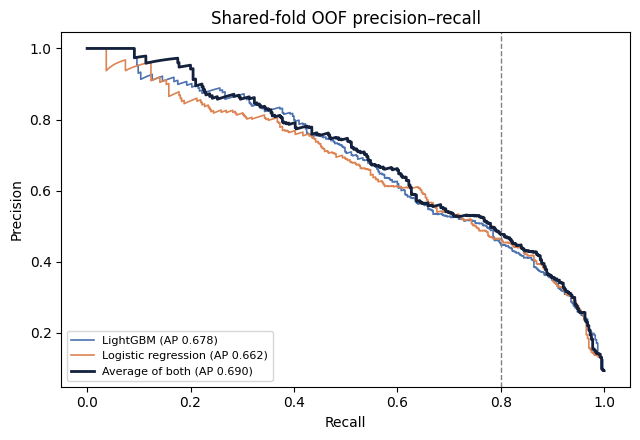

In [6]:
p_lgbm, p_pair = P["lgbm"].to_numpy(), average(P, PAIR)
fold_diff = fold_ap(y, p_pair, folds) - fold_ap(y, p_lgbm, folds)
rng = np.random.default_rng(SEED)
pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
boot = []
for _ in range(N_BOOT):
    i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    boot.append(average_precision_score(y[i], p_pair[i]) - average_precision_score(y[i], p_lgbm[i]))
boot_ci = np.percentile(boot, [2.5, 97.5])
print("Per-fold AP difference (pair − LightGBM):", fold_diff.round(4), f"-> better in {(fold_diff > 0).sum()} of {N_FOLDS}")
print(f"Pooled OOF AP difference {average_precision_score(y, p_pair) - average_precision_score(y, p_lgbm):+.4f}, "
      f"95% bootstrap interval {boot_ci[0]:+.4f} to {boot_ci[1]:+.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, p, color in [("LightGBM", p_lgbm, "#4C72B0"), ("Logistic regression", P["lr"].to_numpy(), "#DD8452"),
                       ("Average of both", p_pair, "#14213D")]:
    prec, rec, _ = precision_recall_curve(y, p)
    ax.plot(rec, prec, label=f"{name} (AP {average_precision_score(y, p):.3f})", color=color,
            lw=2 if name.startswith("Average") else 1.2)
ax.axvline(TARGET_RECALL, color="grey", ls="--", lw=1)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Shared-fold OOF precision–recall")
ax.legend(fontsize=8); plt.tight_layout()
fig.savefig(RUN_DIR / "pr_curves.png", dpi=150); plt.show()

## 3. Nested CV: ensemble procedures vs LightGBM alone

For each shared fold *k*, everything is decided on the other four folds:
1. Inner 3-fold OOF predictions are made for all five base models.
2. These are used to choose the best of 31 subsets and to fit the stacker.
3. The base models are refitted on all four folds, and fold *k* scores each procedure.

Procedures:
- **LightGBM alone.**
- **LightGBM + LR**, fixed in advance (no inner choice).
- **All five, equal average.**
- **Best subset**, chosen on inner folds.
- **Stacker** on all five.

The three fixed procedures (the first three) make no inner choice, so their outer scores equal their Section 2 scores. Nesting matters for the procedures that choose something: the best subset and the stacker.

In [7]:
nested_rows = []
t0 = time.time()
for k in range(N_FOLDS):
    o_tr, o_va = np.where(folds != k)[0], np.where(folds == k)[0]
    X_o, y_o = X.iloc[o_tr].reset_index(drop=True), y[o_tr]
    inner = np.empty(len(y_o), dtype=int)
    for j, (_, iv) in enumerate(StratifiedKFold(N_INNER, shuffle=True, random_state=SEED + k).split(X_o, y_o)):
        inner[iv] = j

    P_in = oof_matrix(X_o, y_o, inner)
    inner_scores = {s: fold_ap(y_o, average(P_in, s), inner).mean() for s in SUBSETS}
    chosen = max(inner_scores, key=inner_scores.get)
    stacker = fit_stacker(P_in, y_o)

    P_out, y_v = fit_predict(X_o, y_o, X.iloc[o_va]), y[o_va]
    nested_rows.append({
        "outer fold": k,
        "LightGBM alone": average_precision_score(y_v, P_out["lgbm"]),
        "LightGBM + LR (fixed)": average_precision_score(y_v, average(P_out, PAIR)),
        "All five, equal average": average_precision_score(y_v, average(P_out, BASES)),
        "Best subset (inner choice)": average_precision_score(y_v, average(P_out, chosen)),
        "Stacker on all five": average_precision_score(y_v, stack_predict(stacker, P_out)),
        "subset chosen": name_of(chosen),
    })
    print(f"outer fold {k}: chose {name_of(chosen)}  [{time.time() - t0:.0f}s]")

nested = pd.DataFrame(nested_rows).set_index("outer fold")
nested.to_csv(RUN_DIR / "nested_cv.csv")
procs = [c for c in nested.columns if c != "subset chosen"]
nested_summary = pd.DataFrame({
    "mean AP": nested[procs].mean(),
    "SD": nested[procs].std(ddof=1),
    "mean difference vs LightGBM": nested[procs].sub(nested["LightGBM alone"], axis=0).mean(),
    "SD of difference": nested[procs].sub(nested["LightGBM alone"], axis=0).std(ddof=1),
    "folds better than LightGBM": (nested[procs].sub(nested["LightGBM alone"], axis=0) > 0).sum(),
})
display(nested)
nested_summary

outer fold 0: chose XGBoost + Logistic regression  [33s]


outer fold 1: chose LightGBM + Logistic regression  [65s]


outer fold 2: chose Random forest + Logistic regression  [98s]


outer fold 3: chose LightGBM + Logistic regression  [136s]


outer fold 4: chose LightGBM + Random forest + Logistic regression  [167s]


,LightGBM alone,LightGBM + LR (fixed),"All five, equal average",Best subset (inner choice),Stacker on all five,subset chosen
outer fold,,,,,,
0,0.6816,0.6715,0.6790,0.6403,0.6636,XGBoost + Logistic regression
1,0.6525,0.6825,0.6776,0.6825,0.6742,LightGBM + Logistic regression
2,0.6825,0.7058,0.6894,0.6881,0.6994,Random forest + Logistic regression
3,0.6624,0.6678,0.6638,0.6678,0.6705,LightGBM + Logistic regression
4,0.7081,0.7361,0.7359,0.7371,0.7334,LightGBM + Random forest + Logistic regression


,mean AP,SD,mean difference vs LightGBM,SD of difference,folds better than LightGBM
LightGBM alone,0.6774,0.0214,0.0000,0.0000,0
LightGBM + LR (fixed),0.6927,0.0284,0.0153,0.0172,4
"All five, equal average",0.6891,0.0277,0.0117,0.0139,4
Best subset (inner choice),0.6831,0.0354,0.0057,0.0289,4
Stacker on all five,0.6882,0.0287,0.0108,0.0174,4


## 4. Repeated CV on new splits

LightGBM alone, LightGBM + LR, LightGBM + CatBoost and the five-model average, scored on 3 × repeated stratified 5-fold splits. These splits are new, so none of the hyperparameters or the pair was chosen on them. AP differences are paired by split. Each repeat also gives a full set of OOF predictions, so the ≥80%-recall operating point is computed per repeat.

In [8]:
REPEATED = {"LightGBM alone": ("lgbm",), "LightGBM + LR": PAIR, "LightGBM + CatBoost": ("lgbm", "cat"),
            "All five, equal average": tuple(BASES)}
splitter = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED + 1)
rows, rep_oof = [], {r: {m: np.full(len(y), np.nan) for m in REPEATED} for r in range(N_REPEATS)}
t0 = time.time()
for s, (tr, va) in enumerate(splitter.split(X, y)):
    Pv = fit_predict(X.iloc[tr], y[tr], X.iloc[va])
    row = {"split": s}
    for m, subset in REPEATED.items():
        p = average(Pv, subset)
        rep_oof[s // N_FOLDS][m][va] = p
        row[m] = average_precision_score(y[va], p)
    rows.append(row)
print(f"{len(rows)} splits in {time.time() - t0:.0f}s")

repeated = pd.DataFrame(rows).set_index("split")
repeated.to_csv(RUN_DIR / "repeated_cv.csv")
diff = repeated.sub(repeated["LightGBM alone"], axis=0)
repeated_summary = pd.DataFrame({"mean AP": repeated.mean(), "mean difference vs LightGBM": diff.mean(),
                                 "SD of difference": diff.std(ddof=1), "splits better than LightGBM": (diff > 0).sum()})
display(repeated_summary)

rep_ops = pd.DataFrame([{"repeat": r, "model": m, **operating_point(y, rep_oof[r][m])}
                        for r in range(N_REPEATS) for m in REPEATED])
rep_ops.to_csv(RUN_DIR / "repeated_cv_operating_points.csv", index=False)
print(f"Precision at the >=80% recall threshold, per repeat:")
rep_ops.pivot(index="repeat", columns="model", values="precision")

15 splits in 152s


,mean AP,mean difference vs LightGBM,SD of difference,splits better than LightGBM
LightGBM alone,0.6811,0.0000,0.0000,0
LightGBM + LR,0.6932,0.0121,0.0166,11
LightGBM + CatBoost,0.6818,0.0006,0.0107,8
"All five, equal average",0.6933,0.0121,0.0139,12


Precision at the >=80% recall threshold, per repeat:


model,"All five, equal average",LightGBM + CatBoost,LightGBM + LR,LightGBM alone
repeat,,,,
0,0.4765,0.4596,0.4829,0.4538
1,0.4887,0.4801,0.4924,0.4779
2,0.4772,0.4580,0.4716,0.4609


## 5. Operating point and development-only refit

The team's threshold rule (highest precision with OOF recall ≥ 80%) applied to LightGBM + LR's shared-fold OOF scores, next to LightGBM alone on the same table. Both models are then refitted on all training providers and saved together with equal weights and the threshold.

This is **for reference only**. It is not evaluated on the test set and does not replace the frozen model. Adopting it would need a team decision, and any test score obtained afterwards would be test-informed.

In [9]:
ops = pd.DataFrame({"LightGBM alone": {**operating_point(y, p_lgbm), "pooled OOF AP": average_precision_score(y, p_lgbm)},
                    "LightGBM + LR": {**operating_point(y, p_pair), "pooled OOF AP": average_precision_score(y, p_pair)}}).T
display(ops)

members = {n: build(n).fit(X, y) for n in PAIR}
joblib.dump({"members": members, "weights": {n: 1 / len(PAIR) for n in PAIR},
             "threshold": ops.loc["LightGBM + LR", "threshold"], "feature_order": features},
            RUN_DIR / "ensemble_pipeline.joblib")
pd.concat([pd.DataFrame({ID: train[ID], "fold": folds, "y_true": y}), P.add_prefix("oof_"),
           pd.DataFrame({"oof_lgbm_lr_average": p_pair, "oof_stacker": stack_oof})], axis=1) \
    .to_csv(RUN_DIR / "oof_predictions.csv", index=False)

metadata = {
    "run_id": RUN_ID, "quick_run": QUICK_RUN, "development_only": True, "test_set_used": False,
    "feature_variant": "leakfree", "train_path": str(TRAIN_PATH), "feature_order": features,
    "base_runs": {"boosting": BOOST_RUN.name, "logistic_random_forest": LRRF_RUN.name},
    "base_params": PARAMS, "ensemble": {"members": list(PAIR), "combination": "equal-weight probability average"},
    "reproduction_max_abs_diff": repro,
    "shared_folds": {"lgbm_mean_fold_ap": float(fold_ap(y, p_lgbm, folds).mean()),
                     "pair_mean_fold_ap": float(fold_ap(y, p_pair, folds).mean()),
                     "pooled_ap_diff_bootstrap_95": [float(v) for v in boot_ci]},
    "nested_cv": nested_summary.to_dict(orient="index"),
    "nested_cv_subsets_chosen": nested["subset chosen"].tolist(),
    "repeated_cv": repeated_summary.to_dict(orient="index"),
    "operating_point_80_recall": ops.to_dict(orient="index"),
    "versions": {"lightgbm": lightgbm.__version__, "xgboost": xgboost.__version__, "catboost": catboost.__version__,
                 "sklearn": sklearn.__version__},
}
(RUN_DIR / "selected_metadata.json").write_text(json.dumps(metadata, indent=2, default=float))
print(f"Saved development-only ensemble and metadata to {RUN_DIR}")

,threshold,precision,recall,share reviewed,pooled OOF AP
LightGBM alone,0.0455,0.4538,0.8000,0.1650,0.6776
LightGBM + LR,0.1310,0.4800,0.8000,0.1560,0.6905


Saved development-only ensemble and metadata to ../artifacts/ensemble/20261115_201844_full_leakfree


## Findings

**Averaging LightGBM with logistic regression is a real gain, unlike the extra tuning in 06f. CatBoost and stacking add nothing beyond it.**

| Check | LightGBM alone | LightGBM + LR average | Difference |
|---|---:|---:|---:|
| Shared folds, mean fold AP (pair suggested by these folds) | 0.6774 | 0.6927 | +0.015 (better in 4 of 5 folds) |
| Pooled OOF AP, provider bootstrap | 0.6776 | 0.6905 | +0.013 (95% interval +0.000 to +0.026) |
| **Repeated CV, 15 new splits** | **0.6811** | **0.6932** | **+0.012** (SD 0.017; better in 11 of 15) |
| Precision at ≥80% recall, per repeat | 0.454 / 0.478 / 0.461 | 0.483 / 0.492 / 0.472 | +0.011 to +0.029 |
| Precision at ≥80% recall, shared folds | 0.454 (16.5% reviewed) | 0.480 (15.6% reviewed) | +0.026 |

- **Why it works: the two models make different mistakes.** Their rank correlation is 0.87, the lowest of any LightGBM pairing. At their own 80%-recall thresholds, each catches about 20 fraud providers the other misses.
- **The gain survives fresh splits.** This is the opposite of 06f: there the winner's +0.008 turned into −0.002 on new splits, while here +0.015 becomes +0.012 and wins 11 of 15. On average about 2 fewer in every 100 reviews are wasted at the same 80% recall.
- **CatBoost is a good model but not a complementary one.** Untuned, it matches LightGBM on its own (0.680 vs 0.677). Averaged with LightGBM it adds +0.001 on new splits, because it ranks providers like the other tree models.
- **Choosing more cleverly does worse than the simple pair.**
  - When the best subset was picked on inner folds, the choice changed in 3 of 5 outer folds, and the result was only +0.006 over LightGBM.
  - The logistic-regression stacker (+0.011) and the five-model average (+0.012) match the pair without beating it.
  - With about 400 fraud cases, the fixed two-model average is the most reliable option.

**Caveats**
- The pair was spotted on the shared folds. The repeated-CV result (+0.012) is the honest estimate. The base hyperparameters were tuned on the shared folds, which affects both arms equally.
- The gain is modest next to fold-to-fold variation (SD about 0.02), and the bootstrap interval only just excludes zero.
- **The held-out test set has already been used.** The frozen LightGBM remains the evaluated final model. This ensemble is a development-only, validated improvement, best reported as the recommended next step. If the team adopts it, its threshold (0.131, from the OOF predictions here) must be fixed first, and any test score after that must be disclosed as test-informed.
